<a href="https://colab.research.google.com/github/Jibin1216/machine-learning/blob/main/polynomial_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score



In [5]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
data = pd.read_csv(url)

data = data[['mpg','displacement']]
data.dropna(inplace=True)

print(data.head())

    mpg  displacement
0  18.0         307.0
1  15.0         350.0
2  18.0         318.0
3  16.0         304.0
4  17.0         302.0


In [10]:
X = data[['displacement']]
y = data['mpg']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)
print("Linear Regression")
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_linear))
print("R-squared:", r2_score(y_test, y_pred_linear))

Linear Regression
Mean Squared Error: 18.102543998358946
R-squared: 0.6633114869465596


In [18]:
degrees = [2,3,4]

for degree in degrees:
  poly = PolynomialFeatures(degree)
  X_train_poly=poly.fit_transform(X_train)
  X_test_poly=poly.transform(X_test)

  model=LinearRegression()
  model.fit(X_train_poly,y_train)
  y_pred=model.predict(X_test_poly)
  print("\ndegree=", degree)
  print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
  print("R-squared:", r2_score(y_test, y_pred))
  print("\n")


degree= 2
Mean Squared Error: 15.10735356108076
R-squared: 0.7190189176110284



degree= 3
Mean Squared Error: 14.943631793037289
R-squared: 0.722063972418907



degree= 4
Mean Squared Error: 14.961486893912738
R-squared: 0.7217318860908903




/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


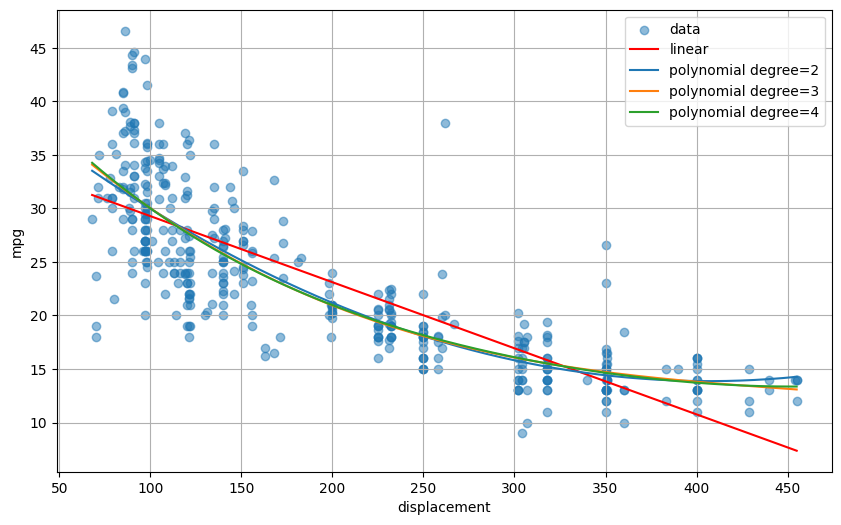

In [23]:
x_range = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X, y,alpha=0.5,label='data')
plt.plot(x_range,
         linear_model.predict(x_range),
         color='red',
         label='linear')
colors=['blue','red','orange']
for degree,color in zip([2,3,4],colors):
  poly = PolynomialFeatures(degree)
  X_poly=poly.fit_transform(X)
  model=LinearRegression()
  model.fit(X_poly,y)
  plt.plot(x_range,
           model.predict(poly.fit_transform(x_range)),
           label=f'polynomial degree={degree}')
plt.xlabel('displacement')
plt.ylabel('mpg')
plt.legend()
plt.grid()
plt.show()